# 2.6. Интерактивный дашборд по игровой аудитории

Дашборд объединяет основные результаты анализа Steam и агрегированные характеристики RAWG, Wikidata, Twitch и YouTube. Единица наблюдения — игра Steam; для каждого источника в профиле не более одной агрегированной строки на AppID.

Фильтры по жанру и цене обновляют графики. В дашборде показаны различия между жанрами и бесплатными/платными играми, изменения по десятилетиям выпуска, связь рекомендаций Steam со средней активностью игроков и покрытие внешних источников.

Совпадения между платформами основаны на названиях и не подтверждены общими идентификаторами. Поэтому внешние метрики следует воспринимать как описательное обогащение данных. Twitch, YouTube и Steam относятся к разным временным периодам и измеряют разные виды активности.

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import plotly.express as px
import ipywidgets as widgets
from IPython.display import Markdown, display


ROOT = next(
    (
        path
        for path in [Path.cwd(), *Path.cwd().parents]
        if (path / "notebooks").is_dir() and (path / "README.md").is_file()
    ),
    None,
)

if ROOT is None:
    raise FileNotFoundError("Не удалось найти корень проекта.")

PROFILE_PATH = ROOT / "processed" / "analysis" / "cross_source_game_profile_2_4.parquet"
QUALITY_DIR = ROOT / "docs" / "data_quality"

if not PROFILE_PATH.is_file():
    raise FileNotFoundError(
        "Не найден профиль 2.4. Сначала выполни ноутбуки 2.2–2.4."
    )

games = pd.read_parquet(PROFILE_PATH)

required_columns = {
    "steam_app_id", "name", "release_year", "primary_genre",
    "price", "recommendations", "avg_players_12m",
}
missing_columns = required_columns - set(games.columns)

if missing_columns:
    raise ValueError(f"В профиле 2.4 отсутствуют столбцы: {sorted(missing_columns)}")

for column in ["release_year", "price", "recommendations", "avg_players_12m"]:
    games[column] = pd.to_numeric(games[column], errors="coerce")

games = games[games["price"].ge(0)].copy()
games["primary_genre"] = games["primary_genre"].fillna("Не указан")
games["price_group"] = np.where(games["price"].eq(0), "Бесплатная", "Платная")
games["release_decade"] = (
    games["release_year"].floordiv(10).mul(10).astype("Int64").astype("string")
    + "-е"
)

print(f"Игр в профиле: {len(games):,}")

Игр в профиле: 150,466


In [2]:
SOURCE_COLUMNS = {
    "RAWG": "rawg_id",
    "Wikidata": "wikidata_uri",
    "Twitch": "twitch_hours_watched",
    "YouTube": "youtube_video_count",
}


def render_dashboard(genre, price_group):
    filtered = games.copy()

    if genre != "Все жанры":
        filtered = filtered[filtered["primary_genre"].eq(genre)]

    if price_group != "Любая цена":
        filtered = filtered[filtered["price_group"].eq(price_group)]

    if filtered.empty:
        display(Markdown("Для выбранных фильтров игр нет."))
        return

    zero_share = filtered["recommendations"].eq(0).mean() * 100
    display(Markdown(
        f"**Игр в выборке:** {len(filtered):,}  \n"
        f"**Без рекомендаций Steam:** {zero_share:.1f}%"
    ))

    # 1. Жанры: фильтр цены применяется, выбранный жанр игнорируется.
    genre_data = games
    if price_group != "Любая цена":
        genre_data = genre_data[genre_data["price_group"].eq(price_group)]

    genre_summary = (
        genre_data.groupby("primary_genre", as_index=False)
        .agg(
            games=("steam_app_id", "size"),
            median_recommendations=("recommendations", "median"),
        )
        .query("games >= 100")
        .sort_values("games", ascending=False)
        .head(12)
    )

    display(px.bar(
        genre_summary.sort_values("median_recommendations"),
        x="median_recommendations",
        y="primary_genre",
        orientation="h",
        title="Медианное число рекомендаций по жанрам (не менее 100 игр)",
        labels={
            "median_recommendations": "Медиана рекомендаций",
            "primary_genre": "Жанр",
        },
        hover_data=["games"],
    ))

    # 2. Динамика по десятилетиям для выбранных фильтров.
    trend_data = filtered.dropna(
        subset=["release_decade", "recommendations"]
    ).copy()
    trend_data = trend_data[trend_data["release_year"].ge(1970)]

    trend = (
        trend_data.groupby("release_decade", as_index=False)
        .agg(
            games=("steam_app_id", "size"),
            zero_share=("recommendations", lambda x: x.eq(0).mean() * 100),
        )
    )

    display(px.line(
        trend,
        x="release_decade",
        y="zero_share",
        markers=True,
        title="Доля игр без рекомендаций по десятилетиям выпуска",
        labels={
            "release_decade": "Десятилетие выпуска",
            "zero_share": "Игры без рекомендаций, %",
        },
        hover_data=["games"],
    ))

    # 3. Бесплатные и платные игры внутри выбранного жанра.
    price_data = games
    if genre != "Все жанры":
        price_data = price_data[price_data["primary_genre"].eq(genre)]

    price_summary = (
        price_data.groupby("price_group", as_index=False)
        .agg(
            games=("steam_app_id", "size"),
            median_recommendations=("recommendations", "median"),
        )
    )

    display(px.bar(
        price_summary,
        x="price_group",
        y="median_recommendations",
        title="Медиана рекомендаций: бесплатные и платные игры",
        labels={
            "price_group": "Категория цены",
            "median_recommendations": "Медиана рекомендаций",
        },
        hover_data=["games"],
    ))

    # 4. Рекомендации и среднее число игроков за доступный 12-месячный период.
    scatter = filtered.dropna(
        subset=["recommendations", "avg_players_12m"]
    )
    scatter = scatter[
        scatter["recommendations"].gt(0) & scatter["avg_players_12m"].gt(0)
    ]

    if len(scatter) > 4000:
        scatter = scatter.sample(4000, random_state=42)

    if not scatter.empty:
        display(px.scatter(
            scatter,
            x="recommendations",
            y="avg_players_12m",
            hover_name="name",
            log_x=True,
            log_y=True,
            title="Рекомендации Steam и среднее число игроков",
            labels={
                "recommendations": "Рекомендации Steam, логарифмическая шкала",
                "avg_players_12m": "Среднее число игроков, логарифмическая шкала",
            },
        ))

    # 5. Доля игр выборки с данными из каждого внешнего источника.
    coverage = pd.DataFrame([
        {
            "source": source,
            "coverage_percent": filtered[column].notna().mean() * 100,
        }
        for source, column in SOURCE_COLUMNS.items()
        if column in filtered.columns
    ])

    display(px.bar(
        coverage,
        x="source",
        y="coverage_percent",
        title="Покрытие внешних источников в выбранной выборке",
        labels={
            "source": "Источник",
            "coverage_percent": "Игры с данными источника, %",
        },
    ))


genre_options = ["Все жанры", *sorted(
    genre for genre in games["primary_genre"].unique()
    if genre != "Не указан"
)]

genre_filter = widgets.Dropdown(
    options=genre_options,
    value="Все жанры",
    description="Жанр:",
    layout=widgets.Layout(width="45%"),
)

price_filter = widgets.Dropdown(
    options=["Любая цена", "Бесплатная", "Платная"],
    value="Любая цена",
    description="Цена:",
    layout=widgets.Layout(width="45%"),
)

controls = widgets.HBox([genre_filter, price_filter])
output = widgets.interactive_output(
    render_dashboard,
    {"genre": genre_filter, "price_group": price_filter},
)

display(controls, output)

Output()

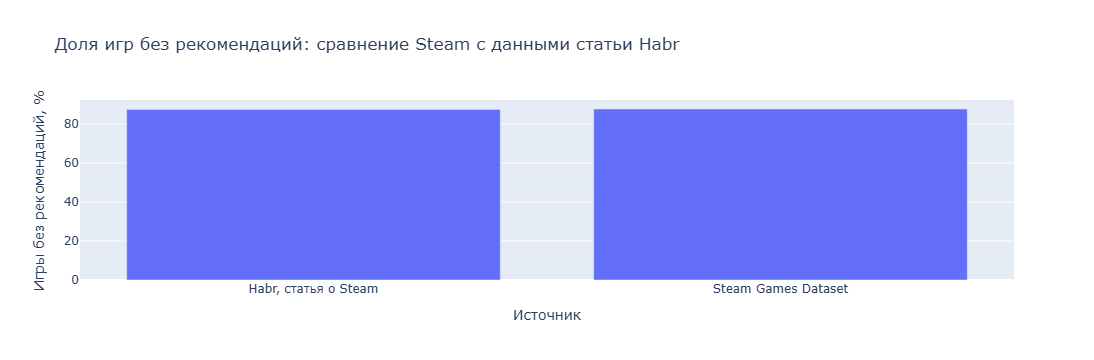

,source,release_period,games,zero_recommendations_pct,url
0,"Habr, статья о Steam",2021–2025,около 65 000 по описанию статьи,87.500000,https://habr.com/ru/articles/995396/
1,Steam Games Dataset,2021–2025,82998,87.702113,NaN


,target,sample_rows,model_mae,baseline_mae,model_rmse,baseline_rmse,model_r2
0,recommendations,142029,1.272,0.984,2.088,2.581,0.235
1,positive_share,82970,0.175,0.178,0.230,0.245,0.059
2,avg_players_12m,3551,1.414,1.496,1.861,2.073,0.140


In [3]:
habr_path = QUALITY_DIR / "habr_steam_comparison_2_4.csv"
metrics_path = QUALITY_DIR / "model_metrics_2_4.csv"

if habr_path.is_file():
    habr_comparison = pd.read_csv(habr_path)
    display(px.bar(
        habr_comparison,
        x="source",
        y="zero_recommendations_pct",
        title="Доля игр без рекомендаций: сравнение Steam с данными статьи Habr",
        labels={
            "source": "Источник",
            "zero_recommendations_pct": "Игры без рекомендаций, %",
        },
        hover_data=["games", "release_period"],
    ))
    display(habr_comparison)
else:
    print("Не найден CSV сравнения Habr и Steam из 2.4.")

if metrics_path.is_file():
    model_metrics = pd.read_csv(metrics_path)
    display(
        model_metrics[
            [
                "target", "sample_rows", "model_mae", "baseline_mae",
                "model_rmse", "baseline_rmse", "model_r2",
            ]
        ].round(3)
    )
else:
    print("Не найден CSV метрик моделей из 2.4.")

## Как читать дашборд

- Сравнение жанров показывает различия медианного числа рекомендаций; для читаемости показаны жанры минимум со 100 играми.
- График по десятилетиям показывает долю каталога без рекомендаций. Размер каждой группы доступен при наведении.
- Сравнение бесплатных и платных игр показывает медиану рекомендаций, а не причинный эффект цены.
- Диаграмма рассеяния использует логарифмические шкалы и только игры с положительными значениями обоих показателей. Для отображения берётся случайная выборка до 4 000 игр.
- Покрытие внешних источников показывает долю строк с доступным значением в каждой платформе. Низкое покрытие и совпадения по названиям ограничивают интерпретацию.
- Habr-сравнение носит ориентировочный характер: выборки и методы подсчёта различаются, а две статьи не представляют весь рынок.
- В таблице моделей MAE и RMSE сравнивают Random Forest с базовым прогнозом, а R² показывает долю объяснённой вариации. Низкое R² означает, что использованных признаков недостаточно для точного прогноза.